# US Accidents – Data Description (2,000-Row Representative Sample)

This notebook describes and visualizes **`US_Accidents_2000_sample.csv`**, a stratified, representative
2,000-row sample of the original *US Accidents (March 2023)* dataset (7.7M rows, 46 features).

**Contents**
1. Setup & data loading
2. Dataset overview (shape, types, preview)
3. Missing values (table, bar chart, **missingness heatmap**)
4. Descriptive statistics (numeric & categorical)
5. Target variable – Severity
6. Time analysis (**hour × weekday heatmap**, **month × year heatmap**)
7. Geographic analysis (map, **State tree map**, **City tree map**, **State × Severity heatmap**)
8. Weather analysis (distributions, **Weather tree map**, **Weather × Severity heatmap**)
9. Road / infrastructure features (**Feature × Severity heatmap**)
10. Day / Night analysis
11. Correlation analysis (**correlation heatmap**)
12. Key findings

## 1. Setup & Data Loading

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import squarify  # tree maps

sns.set_theme(style="whitegrid", palette="viridis", font_scale=1.0)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 13
pd.set_option("display.max_columns", 60)

df = pd.read_csv("US_Accidents_2000_sample.csv")
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")

Rows: 2,000   Columns: 46


In [2]:
# Derived features used for analysis (the original columns are left untouched)
df["Start_Time"] = pd.to_datetime(df["Start_Time"], format="mixed", errors="coerce")
df["End_Time"] = pd.to_datetime(df["End_Time"], format="mixed", errors="coerce")
df["Weather_Timestamp"] = pd.to_datetime(df["Weather_Timestamp"], format="mixed", errors="coerce")

df["Year"] = df["Start_Time"].dt.year
df["Month"] = df["Start_Time"].dt.month
df["Hour"] = df["Start_Time"].dt.hour
df["Weekday"] = df["Start_Time"].dt.day_name()
df["Duration_min"] = (df["End_Time"] - df["Start_Time"]).dt.total_seconds() / 60

WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
SEV_COLORS = {1: "#2a9d8f", 2: "#e9c46a", 3: "#f4a261", 4: "#e63946"}

ORIGINAL_COLS = [c for c in df.columns if c not in ["Year", "Month", "Hour", "Weekday", "Duration_min"]]
NUMERIC_COLS = ["Start_Lat", "Start_Lng", "End_Lat", "End_Lng", "Distance(mi)", "Temperature(F)",
                "Wind_Chill(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)",
                "Wind_Speed(mph)", "Precipitation(in)"]
ROAD_COLS = ["Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit", "Railway",
             "Roundabout", "Station", "Stop", "Traffic_Calming", "Traffic_Signal", "Turning_Loop"]
TWILIGHT_COLS = ["Sunrise_Sunset", "Civil_Twilight", "Nautical_Twilight", "Astronomical_Twilight"]

## 2. Dataset Overview

In [3]:
df.head()

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Description,Street,City,County,State,Zipcode,Country,Timezone,Airport_Code,Weather_Timestamp,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight,Year,Month,Hour,Weekday,Duration_min
0,A-3479,Source2,2,2016-07-19 10:53:47,2016-07-19 11:23:47,37.786362,-121.863632,NaN,NaN,0.00,Accident on Camino Tassajara at Johnston Rd.,Camino Tassajara,Pleasanton,Contra Costa,CA,94588,US,US/Pacific,KLVK,2016-07-19 10:53:00,68.0,NaN,55.0,30.09,10.0,West,10.4,NaN,Clear,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day,2016,7,10,Tuesday,30.000000
1,A-14507,Source2,3,2016-11-01 20:18:07,2016-11-01 20:47:42,37.714737,-121.710014,NaN,NaN,0.01,#1 lane blocked due to accident on I-580 Eastb...,I-580 E,Livermore,Alameda,CA,94551,US,US/Pacific,KLVK,2016-11-01 19:53:00,55.9,NaN,72.0,30.12,10.0,Calm,NaN,NaN,Clear,False,False,False,False,False,False,False,False,False,False,False,False,False,Night,Night,Night,Night,2016,11,20,Tuesday,29.583333
2,A-16147,Source2,2,2016-11-10 11:45:33,2016-11-10 12:15:02,38.019100,-121.942886,NaN,NaN,0.01,Right hand shoulder blocked due to accident on...,CA-4 W,Pittsburg,Contra Costa,CA,94565,US,US/Pacific,KCCR,2016-11-10 11:53:00,72.0,NaN,55.0,30.00,10.0,NE,8.1,NaN,Scattered Clouds,False,False,False,False,False,False,True,False,True,False,False,False,False,Day,Day,Day,Day,2016,11,11,Thursday,29.483333
3,A-20889,Source2,2,2016-09-19 10:28:24,2016-09-19 11:13:24,37.476749,-122.186760,NaN,NaN,0.00,Accident on Bay Rd at Marsh Rd.,Bay Rd,Menlo Park,San Mateo,CA,94025-1959,US,US/Pacific,KPAO,2016-09-19 10:47:00,73.4,NaN,78.0,29.94,10.0,North,9.2,NaN,Clear,False,False,True,False,False,False,False,False,False,False,False,True,False,Day,Day,Day,Day,2016,9,10,Monday,45.000000
4,A-24494,Source2,3,2016-10-14 16:27:12,2016-10-14 16:56:24,38.573753,-121.508972,NaN,NaN,0.01,Accident on I-5 Southbound at Exits 518 519A C...,I-5 N,Sacramento,Sacramento,CA,95818,US,US/Pacific,KSAC,2016-10-14 16:24:00,62.1,NaN,96.0,29.93,1.8,SW,6.9,0.05,Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day,2016,10,16,Friday,29.200000


In [4]:
overview = pd.DataFrame({
    "dtype": df[ORIGINAL_COLS].dtypes.astype(str),
    "non_null": df[ORIGINAL_COLS].notna().sum(),
    "missing_%": (df[ORIGINAL_COLS].isna().mean() * 100).round(2),
    "unique": df[ORIGINAL_COLS].nunique(),
    "example": df[ORIGINAL_COLS].iloc[0].astype(str).str.slice(0, 40),
})
overview

,dtype,non_null,missing_%,unique,example
ID,str,2000,0.00,2000,A-3479
Source,str,2000,0.00,3,Source2
Severity,int64,2000,0.00,4,2
Start_Time,datetime64[ns],2000,0.00,2000,2016-07-19 10:53:47
End_Time,datetime64[ns],2000,0.00,2000,2016-07-19 11:23:47
Start_Lat,float64,2000,0.00,1997,37.786362
Start_Lng,float64,2000,0.00,1999,-121.863632
End_Lat,float64,1129,43.55,1126,NaN
End_Lng,float64,1129,43.55,1126,NaN
Distance(mi),float64,2000,0.00,739,0.0


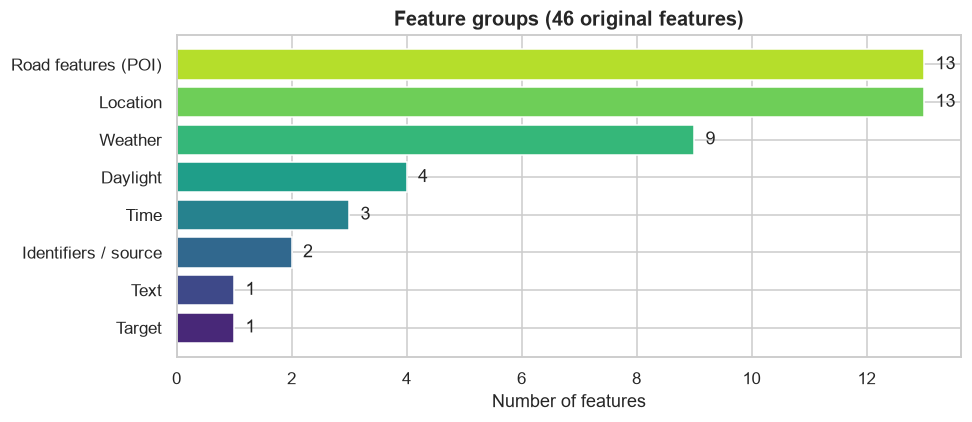

In [5]:
groups = {
    "Identifiers / source": ["ID", "Source"],
    "Target": ["Severity"],
    "Time": ["Start_Time", "End_Time", "Weather_Timestamp"],
    "Location": ["Start_Lat", "Start_Lng", "End_Lat", "End_Lng", "Distance(mi)", "Street", "City",
                 "County", "State", "Zipcode", "Country", "Timezone", "Airport_Code"],
    "Text": ["Description"],
    "Weather": ["Temperature(F)", "Wind_Chill(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)",
                "Wind_Direction", "Wind_Speed(mph)", "Precipitation(in)", "Weather_Condition"],
    "Road features (POI)": ROAD_COLS,
    "Daylight": TWILIGHT_COLS,
}
fig, ax = plt.subplots(figsize=(9, 4))
sizes = pd.Series({k: len(v) for k, v in groups.items()}).sort_values()
ax.barh(sizes.index, sizes.values, color=sns.color_palette("viridis", len(sizes)))
for i, v in enumerate(sizes.values):
    ax.text(v + 0.2, i, str(v), va="center")
ax.set_title(f"Feature groups ({sum(sizes)} original features)")
ax.set_xlabel("Number of features")
plt.tight_layout(); plt.show()

## 3. Missing Values

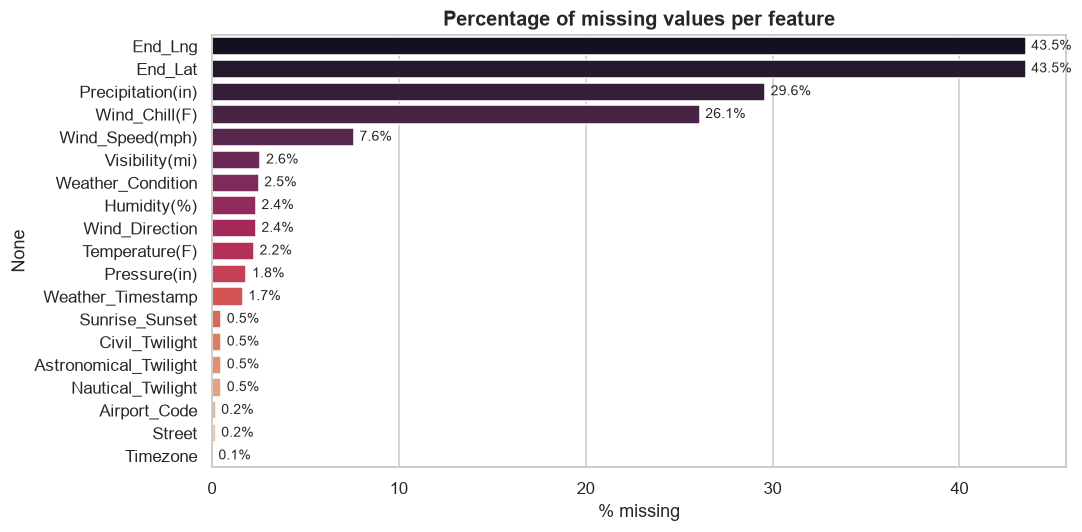

In [6]:
miss = (df[ORIGINAL_COLS].isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=miss.values, y=miss.index, palette="rocket", ax=ax)
for i, v in enumerate(miss.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_title("Percentage of missing values per feature")
ax.set_xlabel("% missing")
plt.tight_layout(); plt.show()

### Missing-value heatmap
Each row of the image is one accident; light cells mark missing values. This reveals *patterns* of missingness (e.g. `End_Lat`/`End_Lng` are always missing together, and weather fields tend to be missing together).

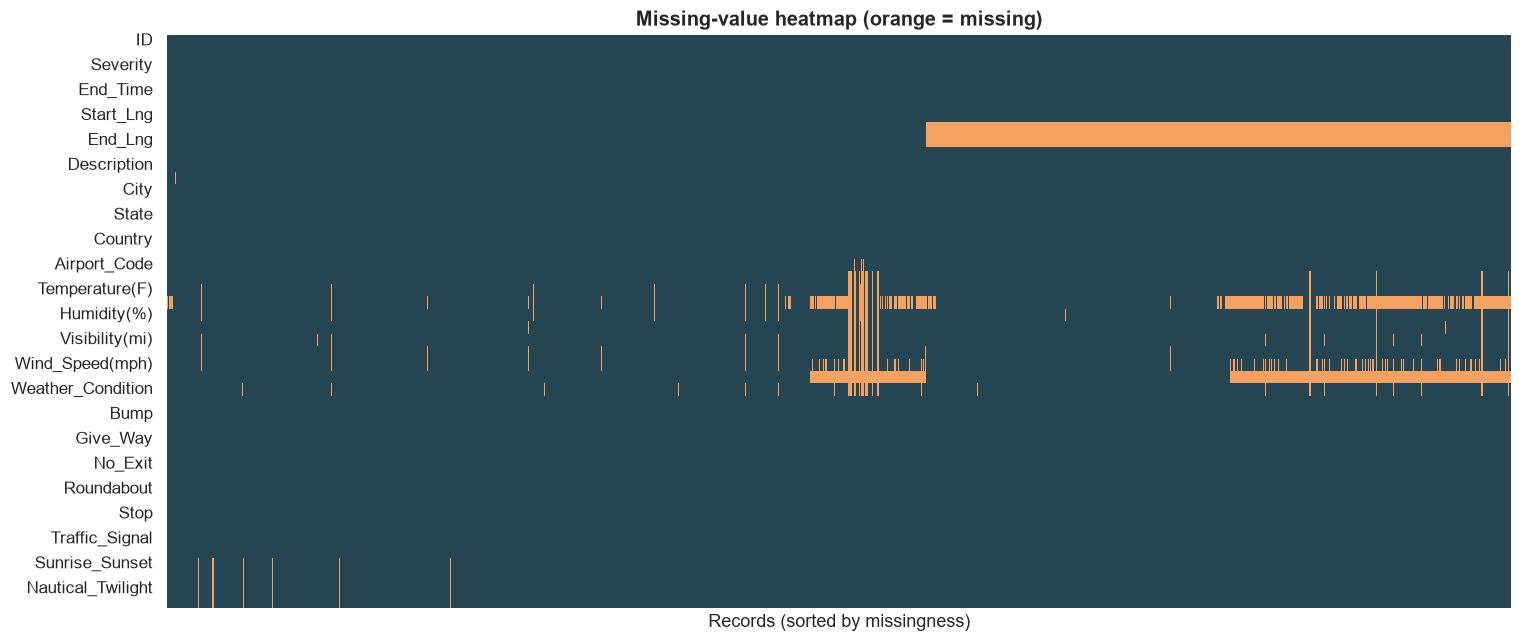

In [7]:
fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(df[ORIGINAL_COLS].isna().sort_values(by=list(miss.index[:3])).T,
            cbar=False, cmap=["#264653", "#f4a261"], ax=ax, xticklabels=False)
ax.set_title("Missing-value heatmap (orange = missing)")
ax.set_xlabel("Records (sorted by missingness)")
plt.tight_layout(); plt.show()

## 4. Descriptive Statistics
### 4.1 Numeric features

In [8]:
desc = df[NUMERIC_COLS + ["Severity", "Duration_min"]].describe(percentiles=[.25, .5, .75]).T
desc["skew"] = df[NUMERIC_COLS + ["Severity", "Duration_min"]].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
Start_Lat,2000.0,36.25,4.93,25.58,33.55,35.75,39.99,48.84,-0.04
Start_Lng,2000.0,-94.62,17.38,-124.17,-117.18,-87.89,-80.32,-70.58,-0.47
End_Lat,1129.0,36.16,5.02,25.58,33.62,35.87,39.93,48.84,-0.12
End_Lng,1129.0,-95.77,18.20,-124.17,-117.76,-88.04,-80.17,-70.69,-0.34
Distance(mi),2000.0,0.56,1.57,0.00,0.00,0.03,0.45,25.91,7.26
Temperature(F),1955.0,61.83,19.26,-9.00,49.00,64.00,77.00,113.00,-0.53
Wind_Chill(F),1478.0,58.33,22.70,-35.00,42.00,63.00,76.00,104.00,-0.68
Humidity(%),1953.0,64.42,23.06,4.00,47.00,67.00,84.00,100.00,-0.37
Pressure(in),1963.0,29.52,1.01,22.51,29.36,29.85,30.03,30.78,-3.44
Visibility(mi),1948.0,9.11,2.80,0.00,10.00,10.00,10.00,70.00,4.67


### 4.2 Categorical features

In [9]:
cat_cols = ["Source", "Street", "City", "County", "State", "Zipcode", "Country", "Timezone",
            "Airport_Code", "Wind_Direction", "Weather_Condition"] + TWILIGHT_COLS
df[cat_cols].describe().T

,count,unique,top,freq
Source,2000,3,Source1,1129
Street,1996,1529,I-10 W,26
City,2000,975,Houston,43
County,2000,426,Los Angeles,148
State,2000,44,CA,460
Zipcode,2000,1752,75238,5
Country,2000,1,US,2000
Timezone,1999,4,US/Eastern,940
Airport_Code,1996,602,KCLT,34
Wind_Direction,1953,24,CALM,250


### 4.3 Boolean road features

In [10]:
road_pct = (df[ROAD_COLS].mean() * 100).sort_values(ascending=False).round(2)
road_pct.to_frame("% True")

,% True
Traffic_Signal,14.70
Crossing,11.20
Junction,6.75
Station,2.50
Stop,2.05
Amenity,1.15
Railway,0.95
Give_Way,0.50
No_Exit,0.35
Bump,0.00


## 5. Target Variable – Severity
Severity ranges from 1 (least impact on traffic) to 4 (most impact).

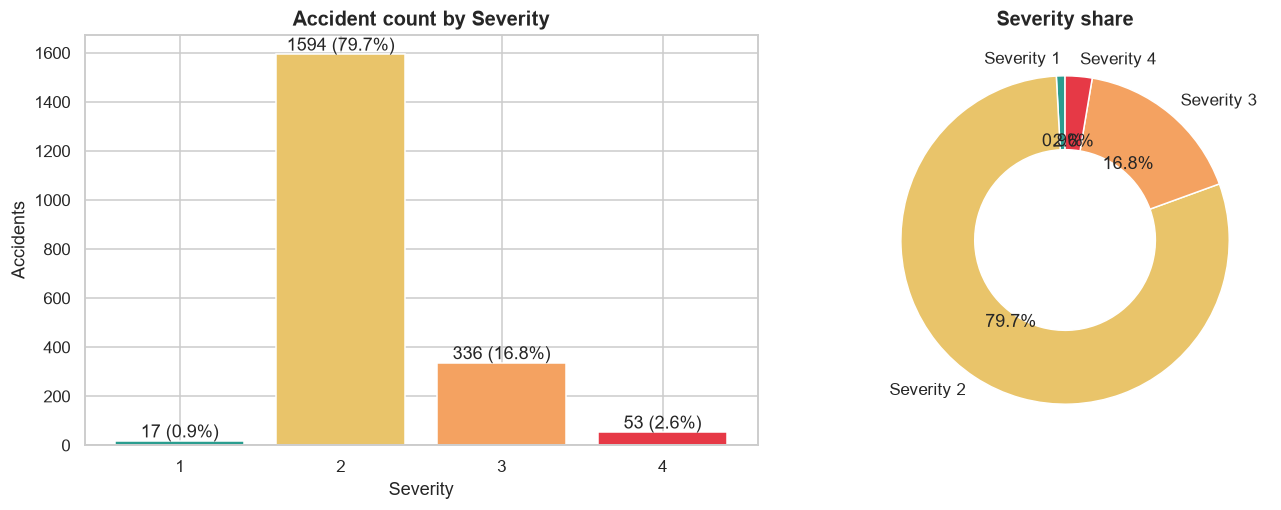

In [11]:
sev = df["Severity"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].bar(sev.index.astype(str), sev.values, color=[SEV_COLORS[s] for s in sev.index])
for i, v in enumerate(sev.values):
    axes[0].text(i, v + 15, f"{v} ({v / len(df):.1%})", ha="center")
axes[0].set_title("Accident count by Severity"); axes[0].set_xlabel("Severity"); axes[0].set_ylabel("Accidents")
axes[1].pie(sev.values, labels=[f"Severity {s}" for s in sev.index], autopct="%1.1f%%",
            colors=[SEV_COLORS[s] for s in sev.index], startangle=90,
            wedgeprops=dict(width=0.45, edgecolor="white"))
axes[1].set_title("Severity share")
plt.tight_layout(); plt.show()

## 6. Time Analysis

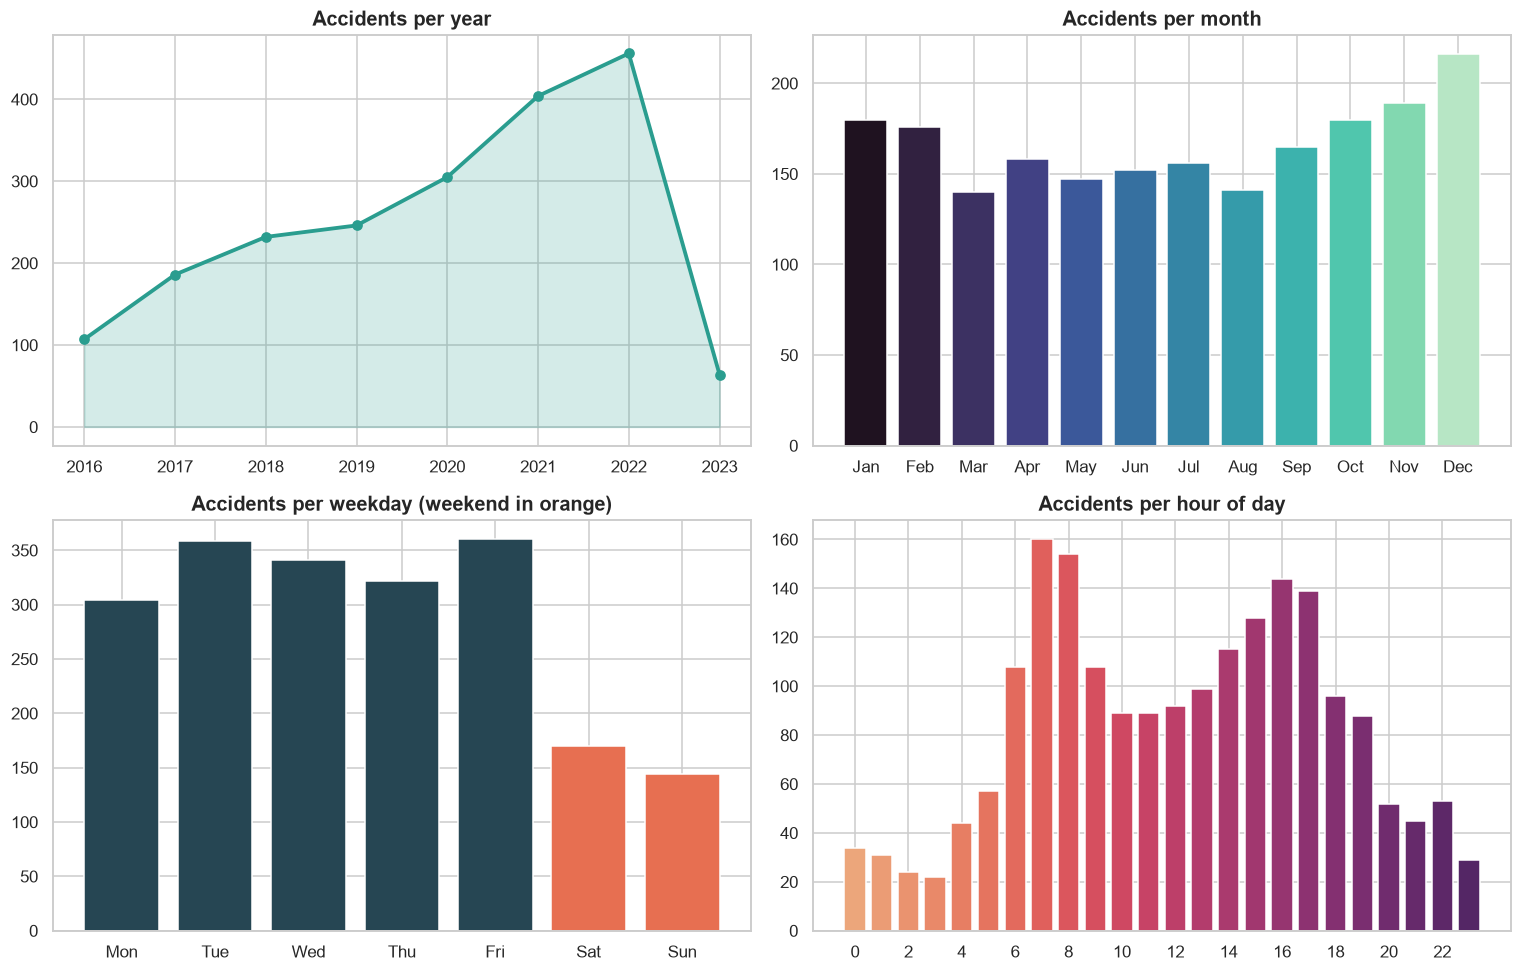

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
yr = df["Year"].value_counts().sort_index()
axes[0, 0].plot(yr.index, yr.values, marker="o", lw=2.5, color="#2a9d8f")
axes[0, 0].fill_between(yr.index, yr.values, alpha=.2, color="#2a9d8f")
axes[0, 0].set_title("Accidents per year")

mo = df["Month"].value_counts().sort_index()
axes[0, 1].bar([MONTHS[m - 1] for m in mo.index], mo.values, color=sns.color_palette("mako", 12))
axes[0, 1].set_title("Accidents per month")

wd = df["Weekday"].value_counts().reindex(WEEKDAYS)
axes[1, 0].bar([d[:3] for d in wd.index], wd.values,
               color=["#264653"] * 5 + ["#e76f51"] * 2)
axes[1, 0].set_title("Accidents per weekday (weekend in orange)")

hr = df["Hour"].value_counts().sort_index()
axes[1, 1].bar(hr.index, hr.values, color=sns.color_palette("flare", 24))
axes[1, 1].set_title("Accidents per hour of day"); axes[1, 1].set_xticks(range(0, 24, 2))
plt.tight_layout(); plt.show()

### Heatmap – Hour of day × Weekday
Shows the morning (7–9 h) and evening (15–18 h) rush-hour peaks on weekdays.

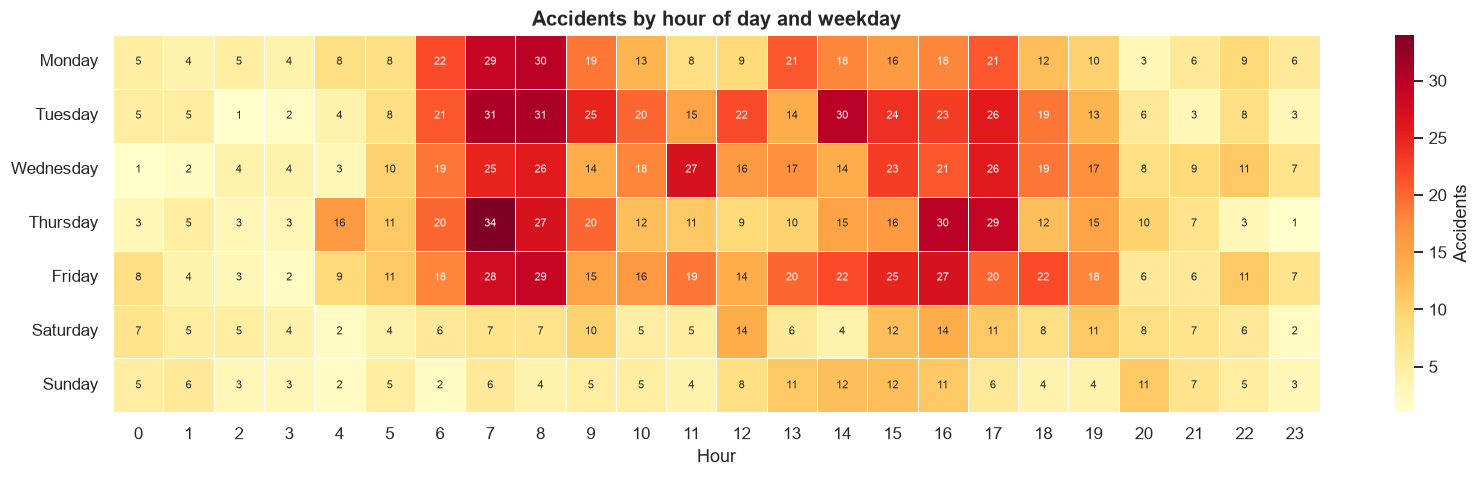

In [13]:
hw = pd.crosstab(df["Weekday"], df["Hour"]).reindex(WEEKDAYS)
fig, ax = plt.subplots(figsize=(15, 4.5))
sns.heatmap(hw, cmap="YlOrRd", linewidths=.4, linecolor="white", annot=True, fmt="d",
            annot_kws={"size": 7}, cbar_kws={"label": "Accidents"}, ax=ax)
ax.set_title("Accidents by hour of day and weekday"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### Heatmap – Hour of day × Weekday by Severity
Extends the temporal dimension with **Severity**. While accident frequency peaks during weekday rush hours, late-night and early-morning hours often show heightened severity.

In [ ]:
# Mean Severity by hour of day and weekday (incorporating the Severity dimension with a new colormap)
sw = df.pivot_table(index="Weekday", columns="Hour", values="Severity", aggfunc="mean").reindex(WEEKDAYS)
fig, ax = plt.subplots(figsize=(15, 4.5))
sns.heatmap(sw, cmap="plasma", linewidths=.4, linecolor="white", annot=True, fmt=".2f",
            annot_kws={"size": 7}, cbar_kws={"label": "Mean Severity"}, ax=ax)
ax.set_title("Mean severity by hour of day and weekday"); ax.set_ylabel("")
plt.tight_layout(); plt.show()


In [ ]:
# Multi-dimensional breakdown: Weekday x Hour faceted across Severity levels
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
cmaps = {2: "Blues", 3: "Oranges", 4: "Reds"}
titles = {
    2: "Severity 2 [Moderate] Accidents by hour of day and weekday",
    3: "Severity 3 [Severe] Accidents by hour of day and weekday",
    4: "Severity 4 [Critical] Accidents by hour of day and weekday"
}

for ax, sev in zip(axes, [2, 3, 4]):
    sub = df[df["Severity"] == sev]
    ct = pd.crosstab(sub["Weekday"], sub["Hour"]).reindex(index=WEEKDAYS, columns=range(24), fill_value=0)
    sns.heatmap(ct, cmap=cmaps[sev], linewidths=.4, linecolor="white", annot=True, fmt="d",
                annot_kws={"size": 7}, cbar_kws={"label": f"Sev {sev} Accidents"}, ax=ax)
    ax.set_title(titles[sev])
    ax.set_ylabel("")

axes[-1].set_xlabel("Hour")
plt.tight_layout(); plt.show()


### Heatmap – Month × Year

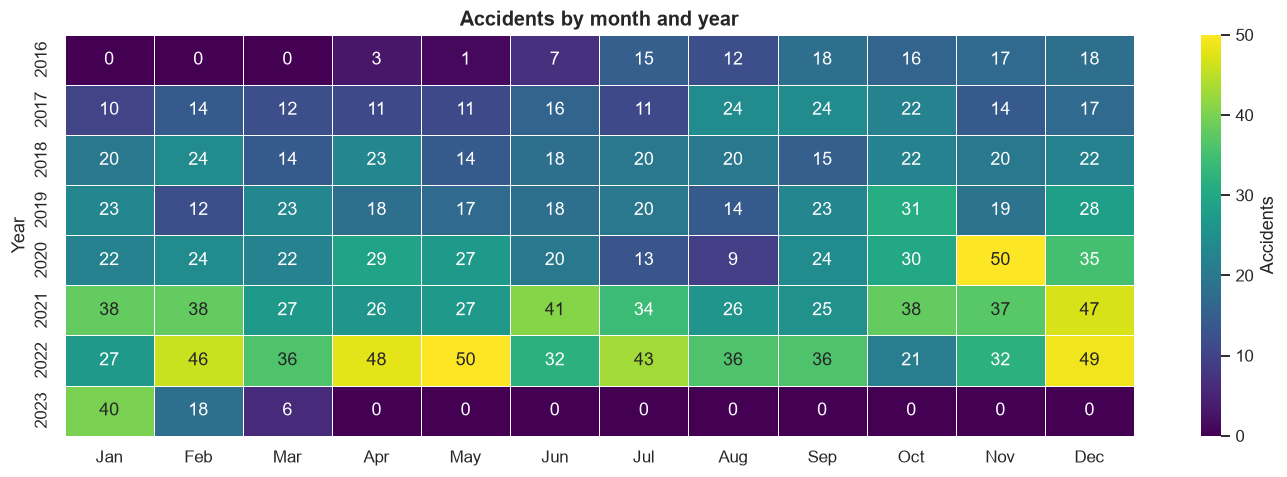

In [14]:
my = pd.crosstab(df["Year"], df["Month"]).reindex(columns=range(1, 13), fill_value=0)
my.columns = MONTHS
fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(my, cmap="viridis", annot=True, fmt="d", linewidths=.4, linecolor="white",
            cbar_kws={"label": "Accidents"}, ax=ax)
ax.set_title("Accidents by month and year")
plt.tight_layout(); plt.show()

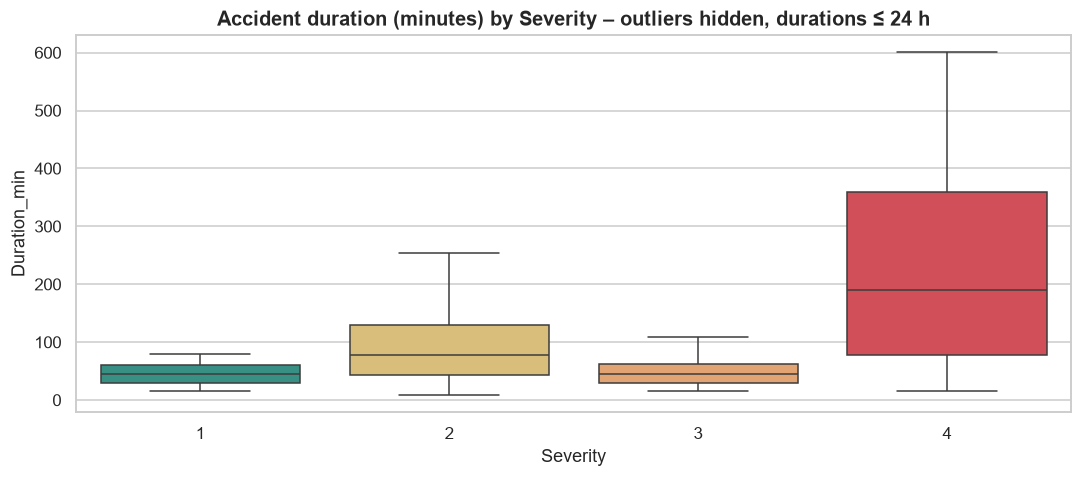

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.5))
d = df.loc[df["Duration_min"].between(0, 24 * 60), ["Duration_min", "Severity"]]
sns.boxplot(data=d, x="Severity", y="Duration_min", palette={str(k): v for k, v in SEV_COLORS.items()}, showfliers=False, ax=ax)
ax.set_title("Accident duration (minutes) by Severity – outliers hidden, durations ≤ 24 h")
plt.tight_layout(); plt.show()

## 7. Geographic Analysis

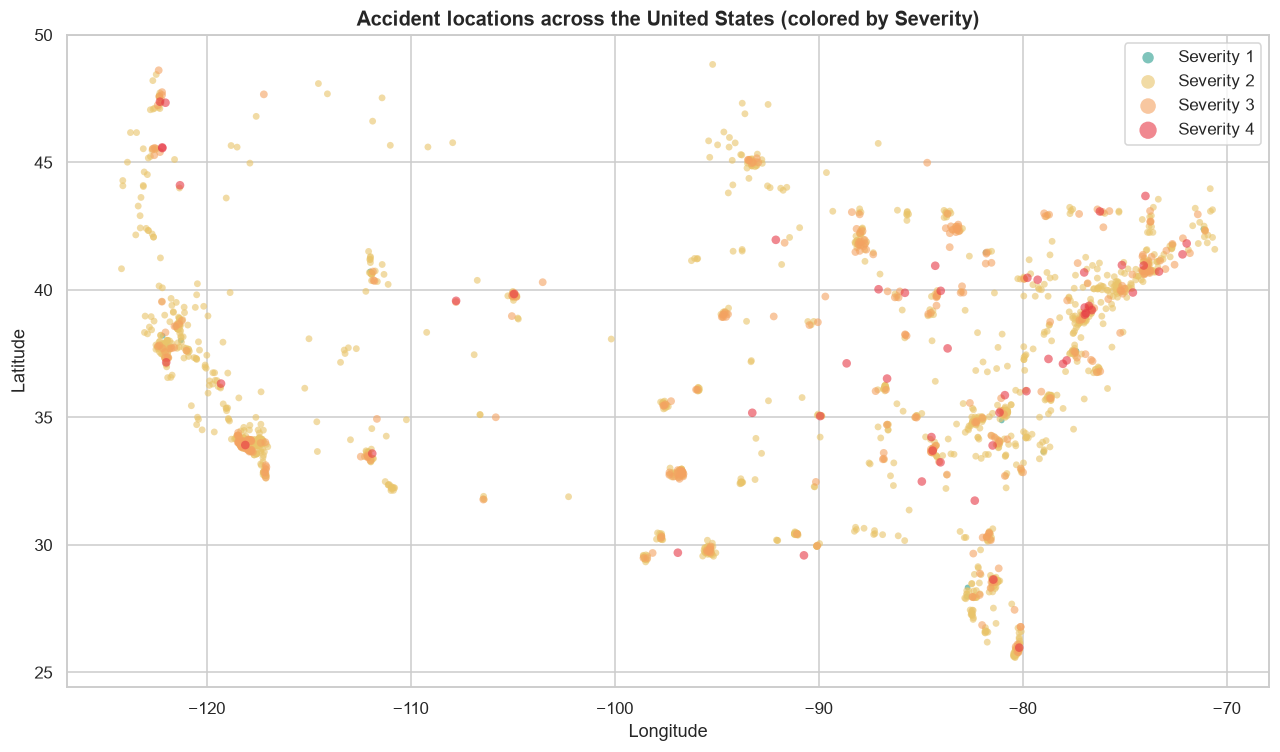

In [16]:
fig, ax = plt.subplots(figsize=(13, 7))
for s in sorted(df["Severity"].unique()):
    sub = df[df["Severity"] == s]
    ax.scatter(sub["Start_Lng"], sub["Start_Lat"], s=8 + 6 * s, alpha=.6,
               color=SEV_COLORS[s], label=f"Severity {s}", edgecolors="none")
ax.set_title("Accident locations across the United States (colored by Severity)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.legend(markerscale=2)
ax.set_aspect(1.25)
plt.tight_layout(); plt.show()

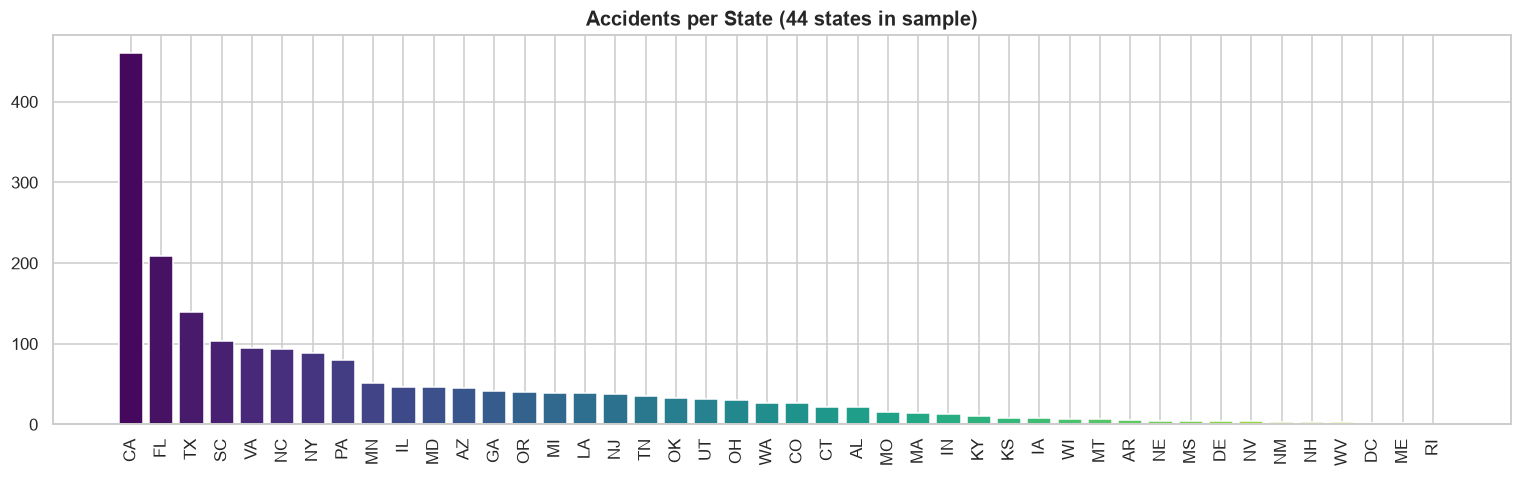

In [17]:
st = df["State"].value_counts()
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(st.index, st.values, color=sns.color_palette("viridis", len(st)))
ax.set_title(f"Accidents per State ({st.size} states in sample)"); ax.tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()

### Tree map – Accidents by State
The area of each rectangle is proportional to the number of accidents in that state.

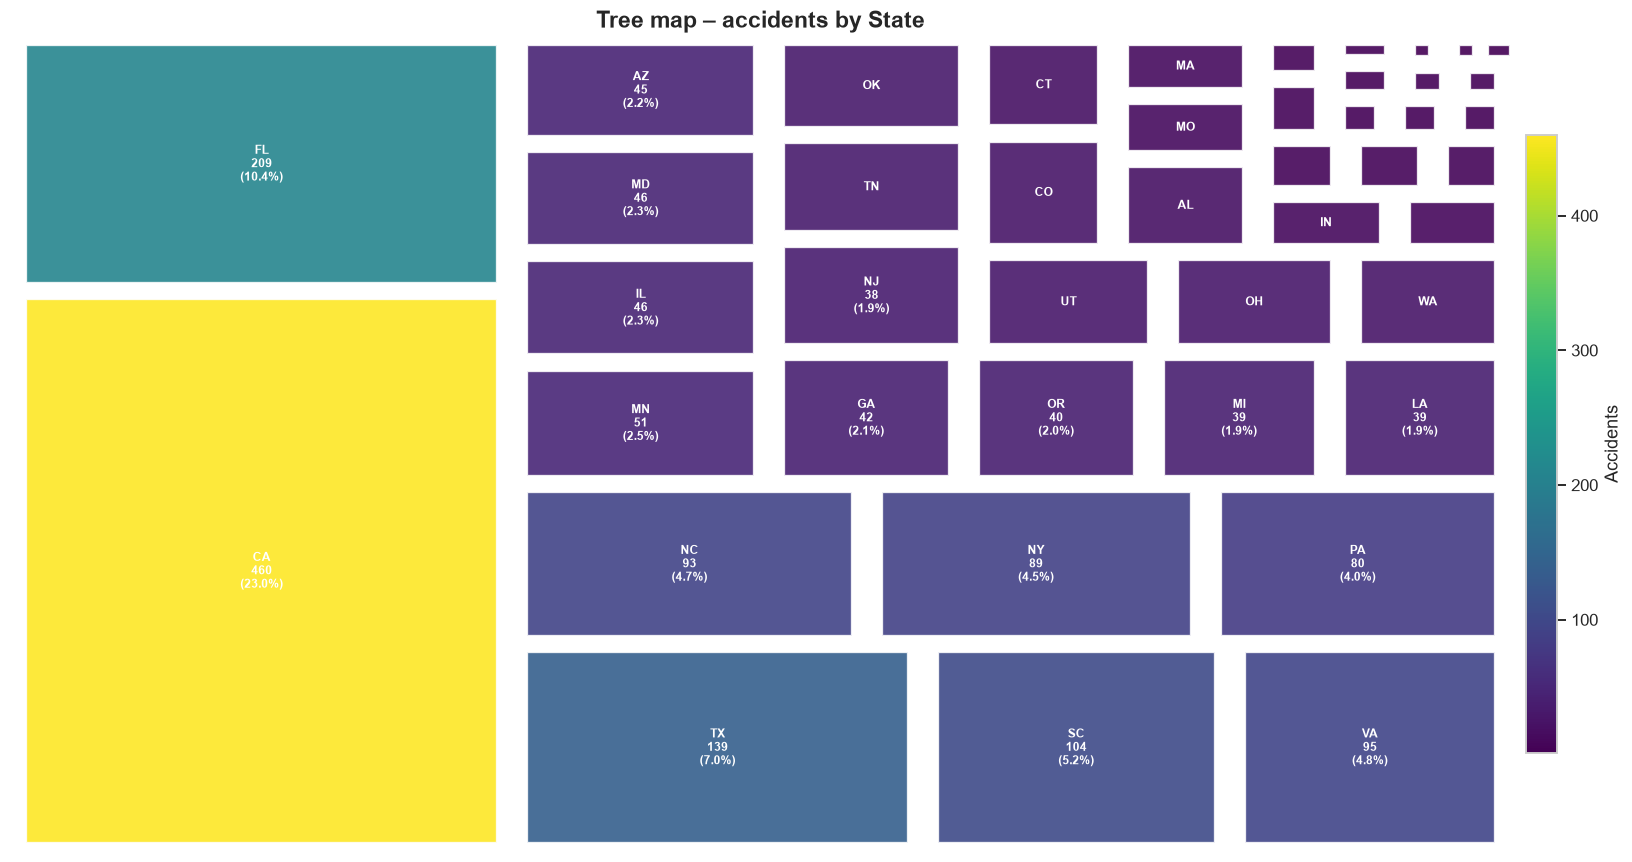

In [18]:
def treemap(series, title, cmap="viridis", top=None, min_label_share=0.006, figsize=(15, 8)):
    s = series.sort_values(ascending=False)
    if top is not None and len(s) > top:
        s = pd.concat([s.iloc[:top], pd.Series({"Other": s.iloc[top:].sum()})])
    share = s / s.sum()
    labels = [f"{k}\n{v:,}\n({p:.1%})" if p >= min_label_share * 3 else (k if p >= min_label_share else "")
              for k, v, p in zip(s.index, s.values, share.values)]
    norm = mcolors.Normalize(vmin=s.min(), vmax=s.max())
    colors = [plt.get_cmap(cmap)(norm(v)) for v in s.values]
    fig, ax = plt.subplots(figsize=figsize)
    squarify.plot(sizes=s.values, label=labels, color=colors, alpha=.9, pad=True, ax=ax,
                  text_kwargs={"fontsize": 8, "color": "white", "weight": "bold"},
                  bar_kwargs={"edgecolor": "white", "linewidth": 1.5})
    ax.set_title(title, fontsize=15); ax.axis("off")
    plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, fraction=.02, pad=.01,
                 label="Accidents")
    plt.tight_layout(); plt.show()

treemap(df["State"].value_counts(), "Tree map – accidents by State", cmap="viridis")

### Tree map – Top 30 cities

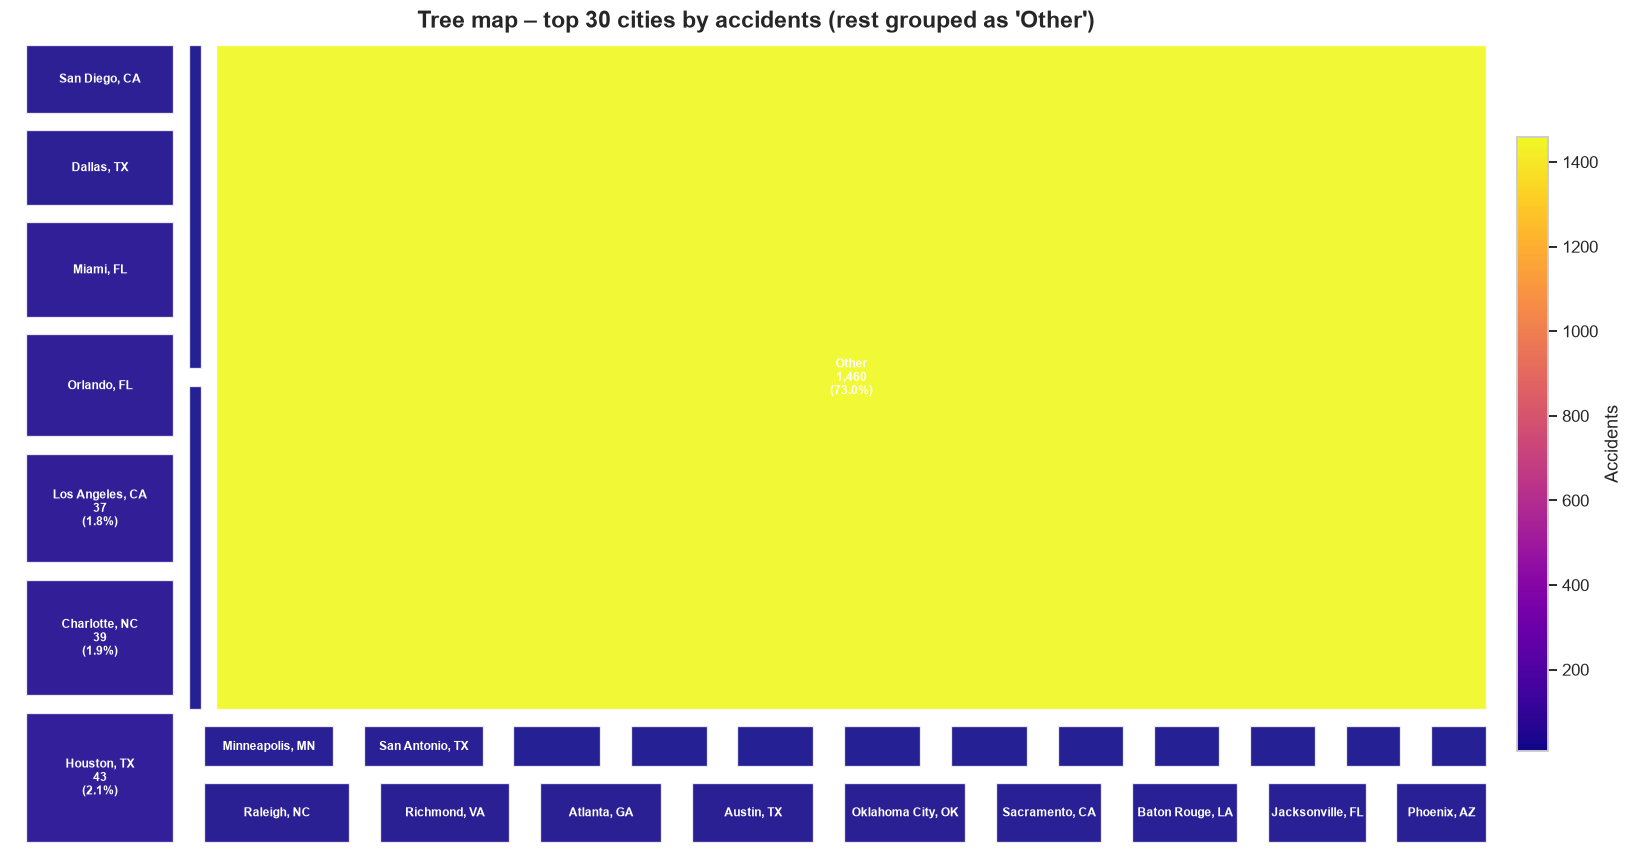

In [19]:
city = (df["City"] + ", " + df["State"]).value_counts()
treemap(city, "Tree map – top 30 cities by accidents (rest grouped as 'Other')", cmap="plasma", top=30)

### Tree map – Timezone

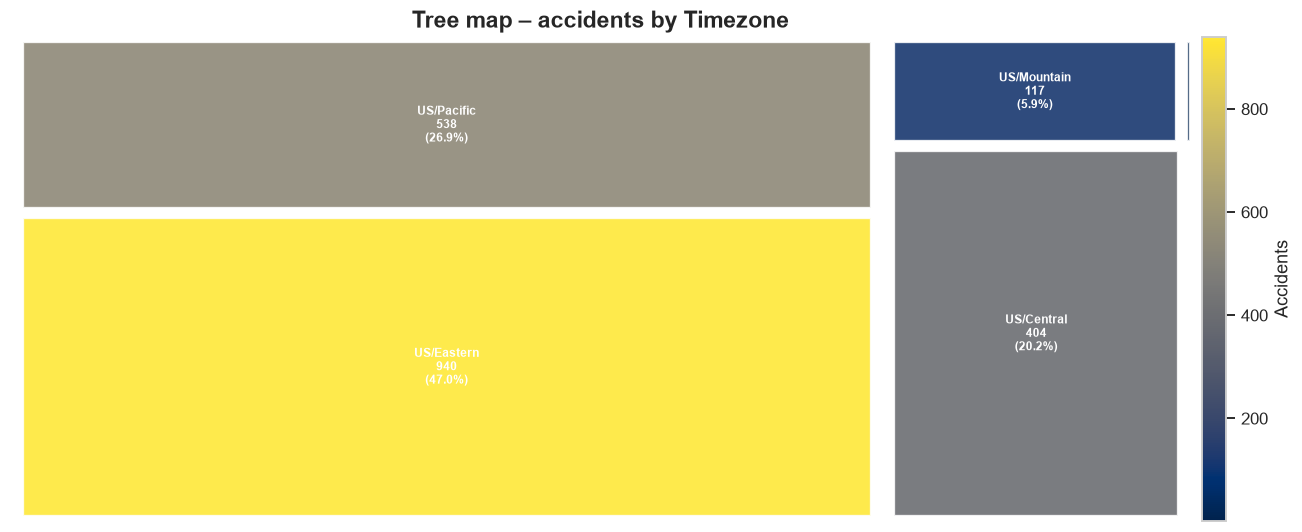

In [20]:
treemap(df["Timezone"].fillna("Unknown").value_counts(), "Tree map – accidents by Timezone",
        cmap="cividis", figsize=(12, 5))

### Heatmap – Top 15 States × Severity (row %)

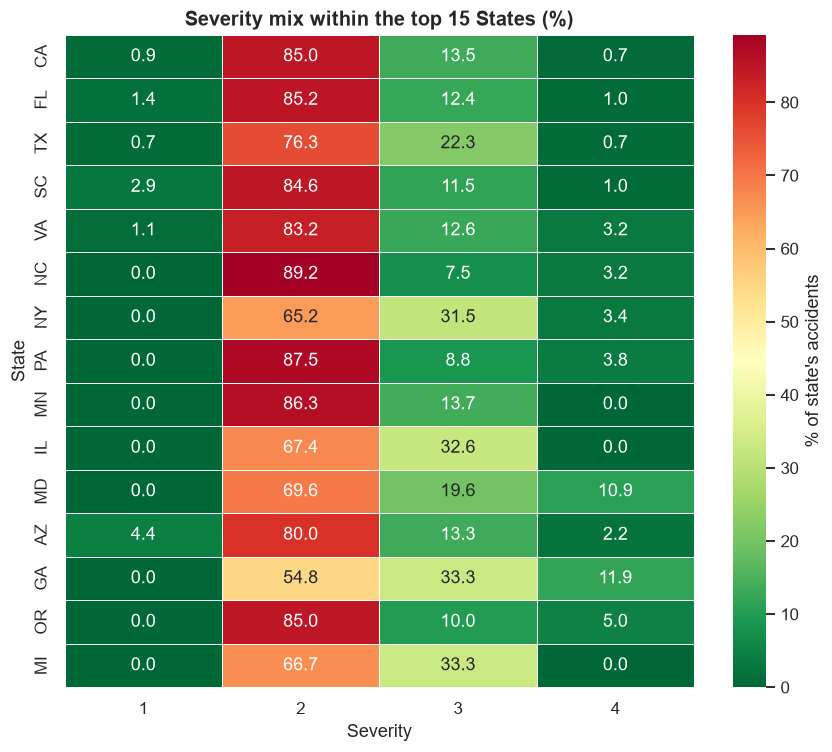

In [21]:
top_states = df["State"].value_counts().index[:15]
ss = pd.crosstab(df.loc[df["State"].isin(top_states), "State"],
                 df.loc[df["State"].isin(top_states), "Severity"], normalize="index") * 100
ss = ss.loc[top_states]
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(ss, annot=True, fmt=".1f", cmap="RdYlGn_r", linewidths=.5, linecolor="white",
            cbar_kws={"label": "% of state's accidents"}, ax=ax)
ax.set_title("Severity mix within the top 15 States (%)")
plt.tight_layout(); plt.show()

## 8. Weather Analysis

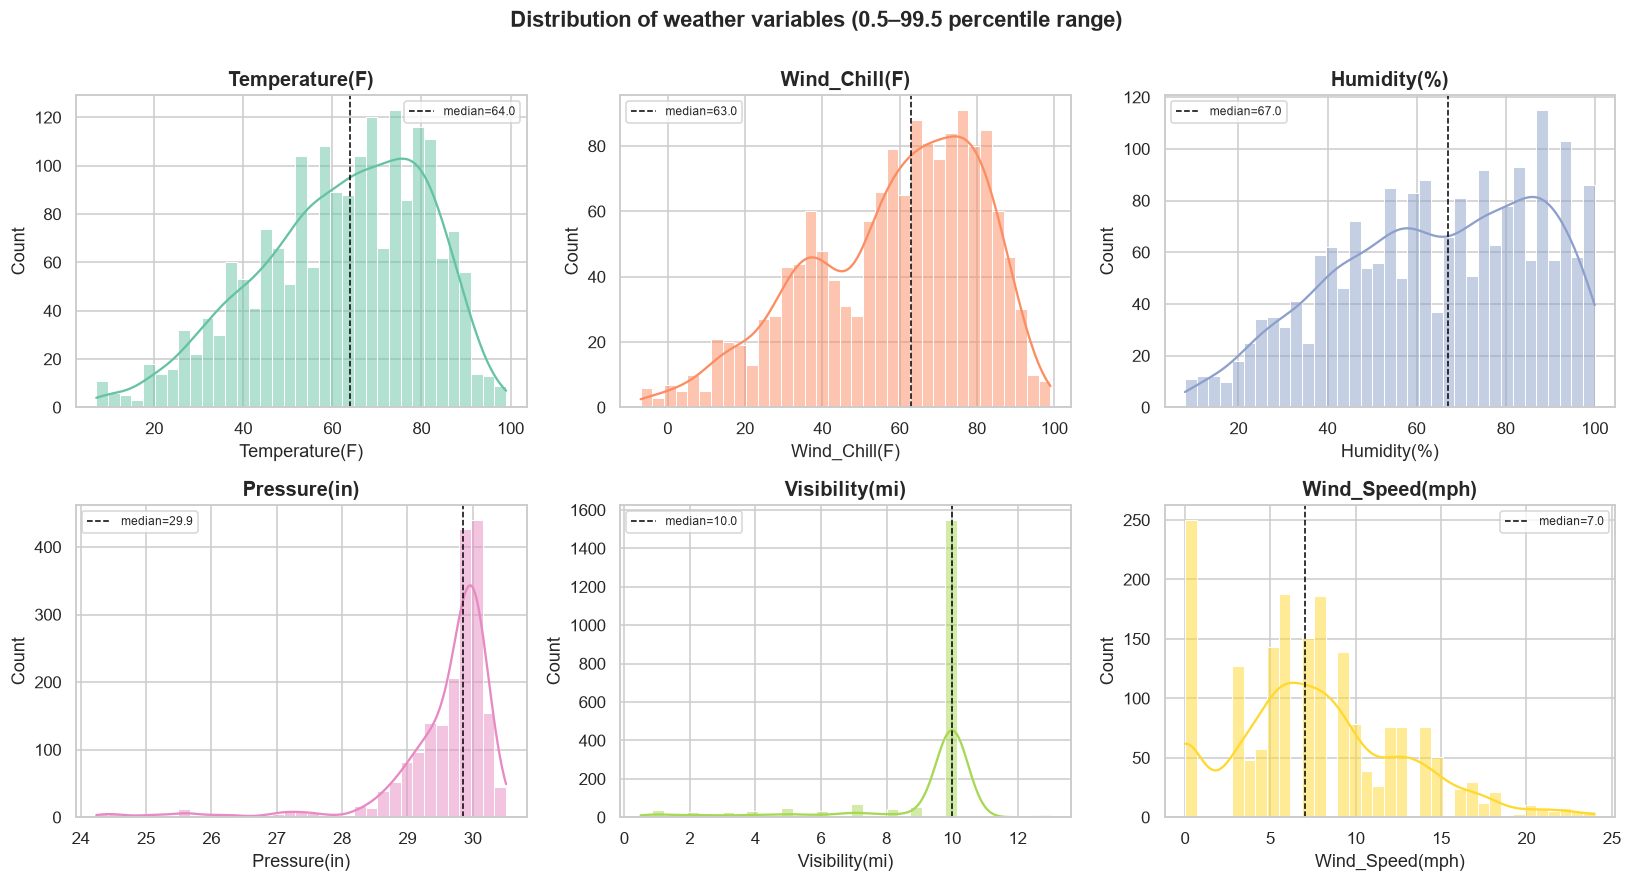

In [22]:
wcols = ["Temperature(F)", "Wind_Chill(F)", "Humidity(%)", "Pressure(in)",
         "Visibility(mi)", "Wind_Speed(mph)"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c, col in zip(axes.flat, wcols, sns.color_palette("Set2", 6)):
    data = df[c].dropna()
    lo, hi = data.quantile([.005, .995])
    sns.histplot(data[data.between(lo, hi)], bins=35, kde=True, color=col, ax=ax)
    ax.axvline(data.median(), color="black", ls="--", lw=1, label=f"median={data.median():.1f}")
    ax.set_title(c); ax.legend(fontsize=8)
plt.suptitle("Distribution of weather variables (0.5–99.5 percentile range)", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

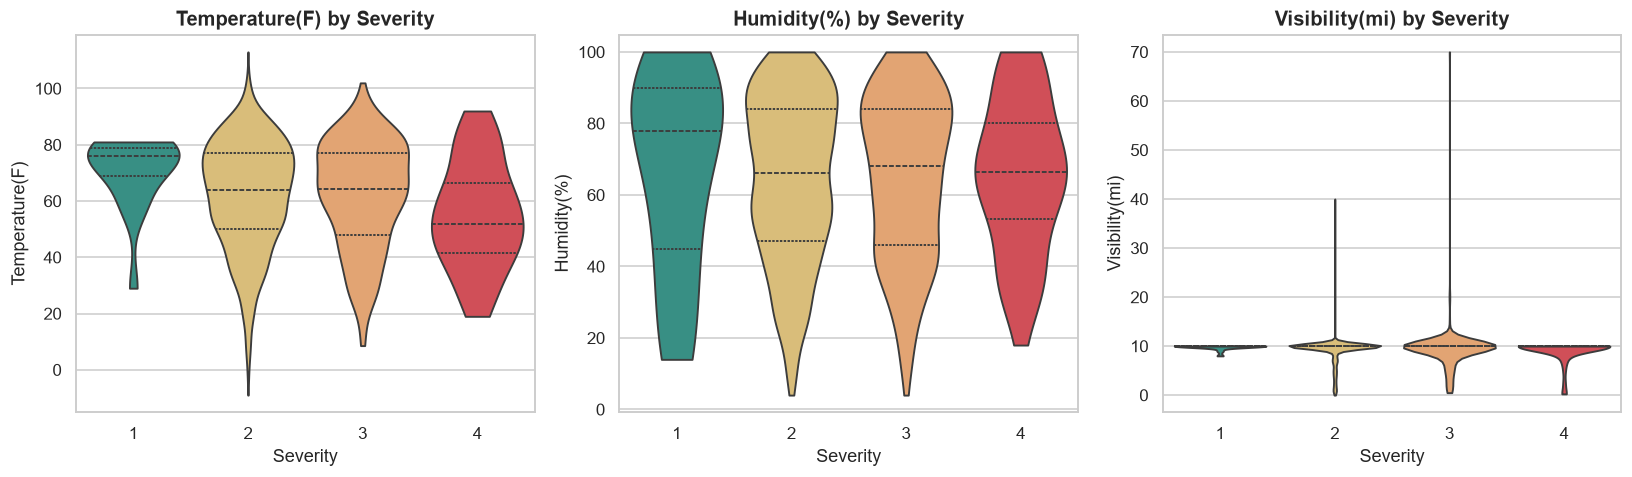

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, c in zip(axes, ["Temperature(F)", "Humidity(%)", "Visibility(mi)"]):
    sns.violinplot(data=df, x="Severity", y=c, palette={str(k): v for k, v in SEV_COLORS.items()}, cut=0, inner="quartile", ax=ax)
    ax.set_title(f"{c} by Severity")
plt.tight_layout(); plt.show()

### Tree map – Weather conditions

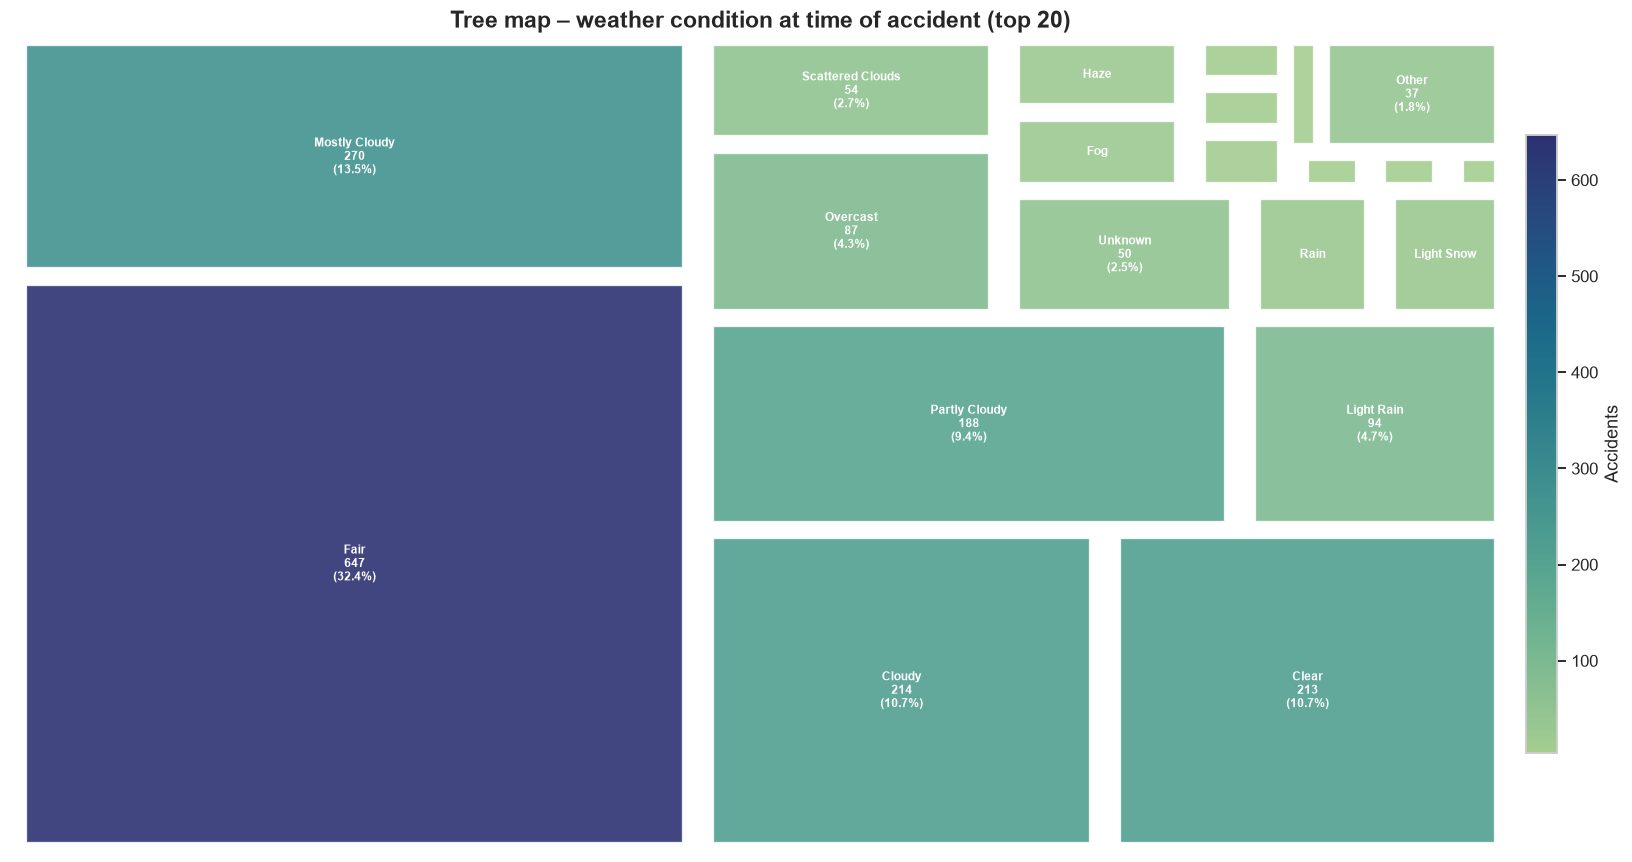

In [24]:
treemap(df["Weather_Condition"].fillna("Unknown").value_counts(),
        "Tree map – weather condition at time of accident (top 20)", cmap="crest", top=20)

### Heatmap – Weather condition × Severity (row %)

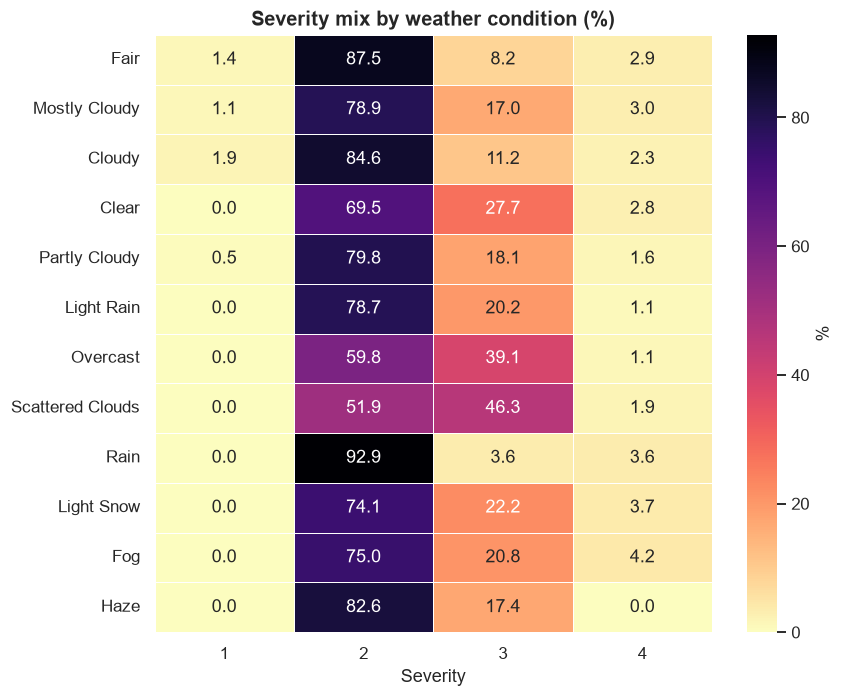

In [25]:
top_w = df["Weather_Condition"].value_counts().index[:12]
sub = df[df["Weather_Condition"].isin(top_w)]
ws = pd.crosstab(sub["Weather_Condition"], sub["Severity"], normalize="index").loc[top_w] * 100
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(ws, annot=True, fmt=".1f", cmap="magma_r", linewidths=.5, linecolor="white",
            cbar_kws={"label": "%"}, ax=ax)
ax.set_title("Severity mix by weather condition (%)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

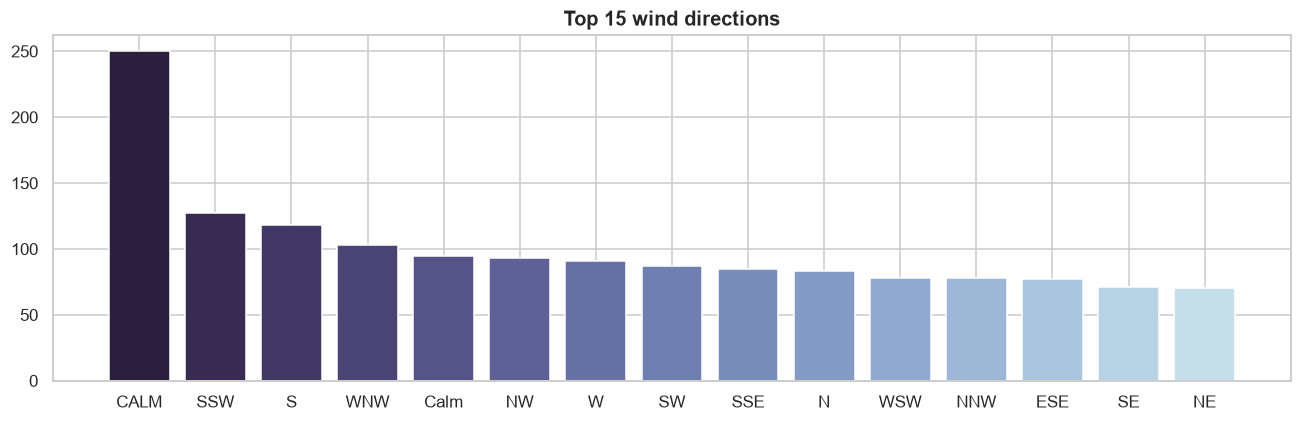

In [26]:
wd = df["Wind_Direction"].value_counts().head(15)
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(wd.index, wd.values, color=sns.color_palette("ch:s=.25,rot=-.25", len(wd))[::-1])
ax.set_title("Top 15 wind directions")
plt.tight_layout(); plt.show()

## 9. Road / Infrastructure Features

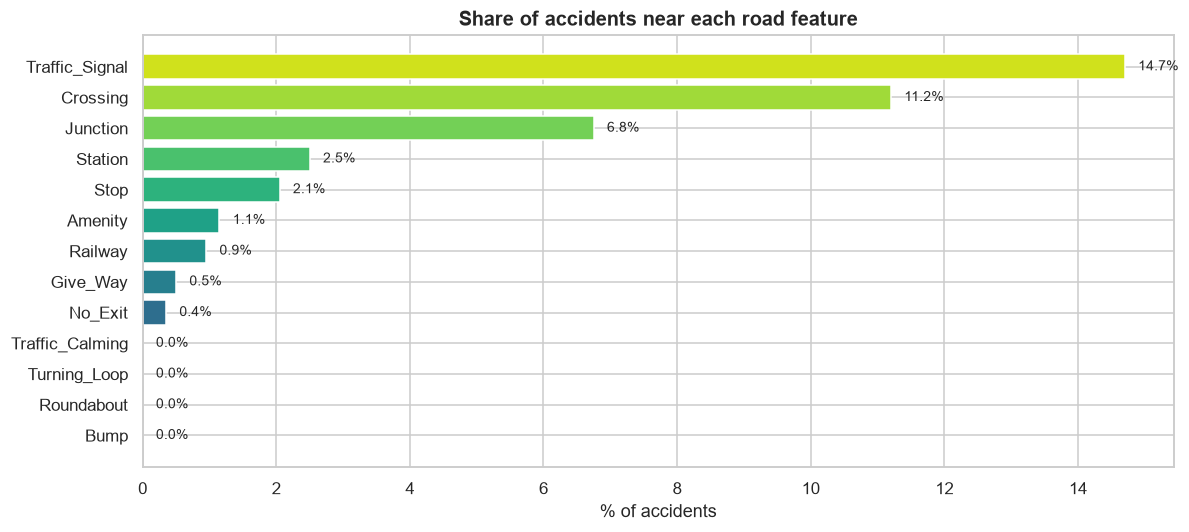

In [27]:
fig, ax = plt.subplots(figsize=(11, 5))
rp = (df[ROAD_COLS].mean() * 100).sort_values()
ax.barh(rp.index, rp.values, color=sns.color_palette("viridis", len(rp)))
for i, v in enumerate(rp.values):
    ax.text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_title("Share of accidents near each road feature"); ax.set_xlabel("% of accidents")
plt.tight_layout(); plt.show()

### Heatmap – Road feature × Severity
Percentage of accidents of each severity level that occurred near the given feature.

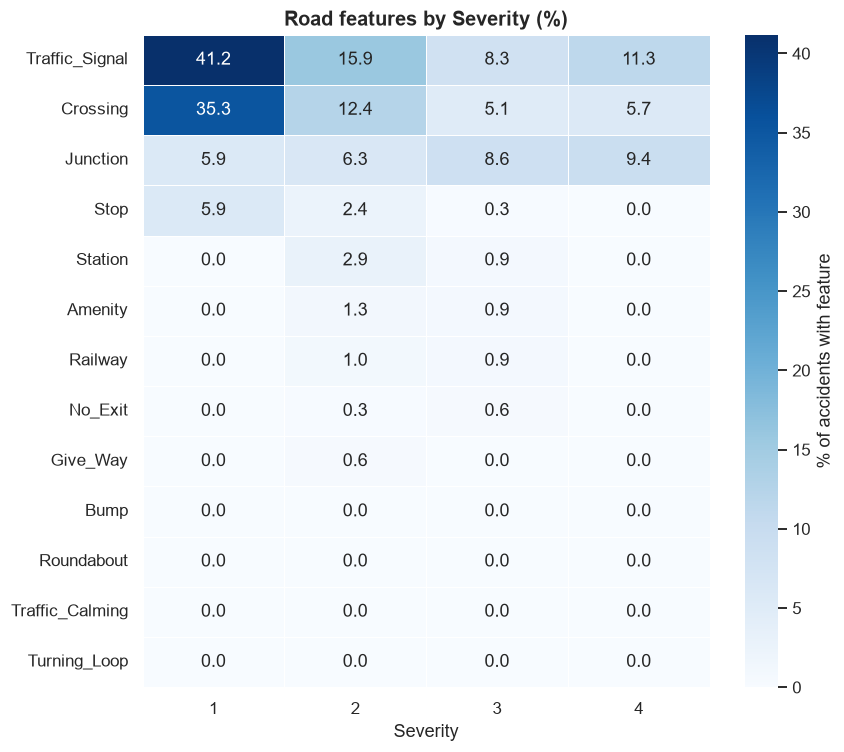

In [28]:
rs = df.groupby("Severity")[ROAD_COLS].mean().T * 100
rs = rs.loc[rs.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(rs, annot=True, fmt=".1f", cmap="Blues", linewidths=.5, linecolor="white",
            cbar_kws={"label": "% of accidents with feature"}, ax=ax)
ax.set_title("Road features by Severity (%)")
plt.tight_layout(); plt.show()

## 10. Day / Night Analysis

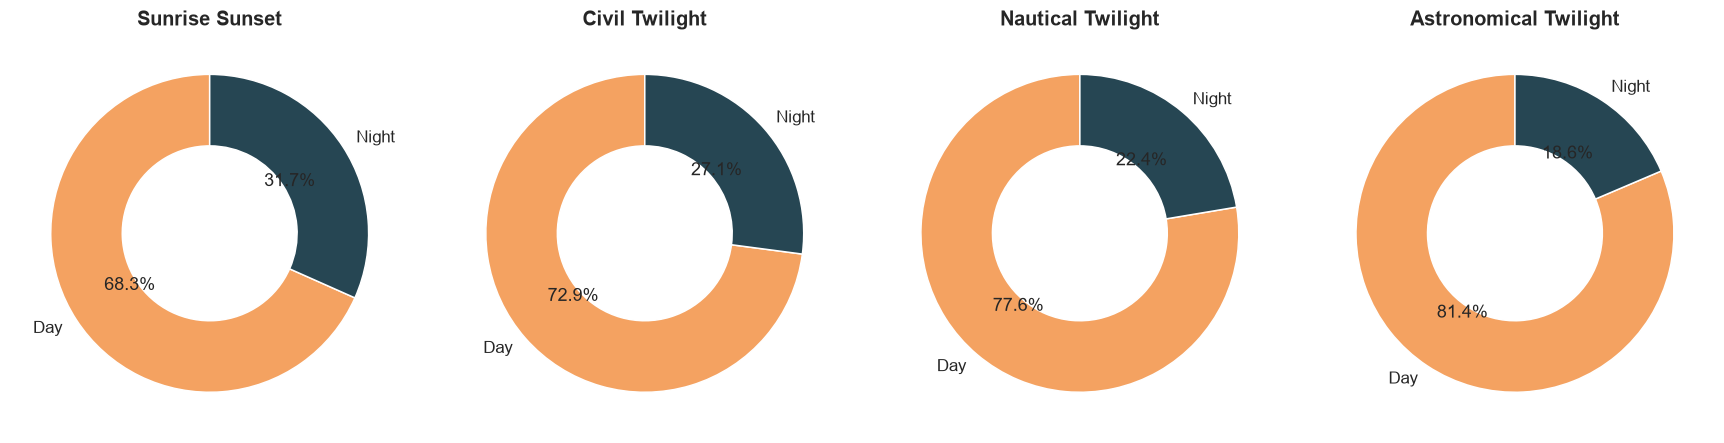

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, TWILIGHT_COLS):
    v = df[c].value_counts()
    ax.pie(v.values, labels=v.index, autopct="%1.1f%%", colors=["#f4a261", "#264653"],
           startangle=90, wedgeprops=dict(width=.45, edgecolor="white"))
    ax.set_title(c.replace("_", " "))
plt.tight_layout(); plt.show()

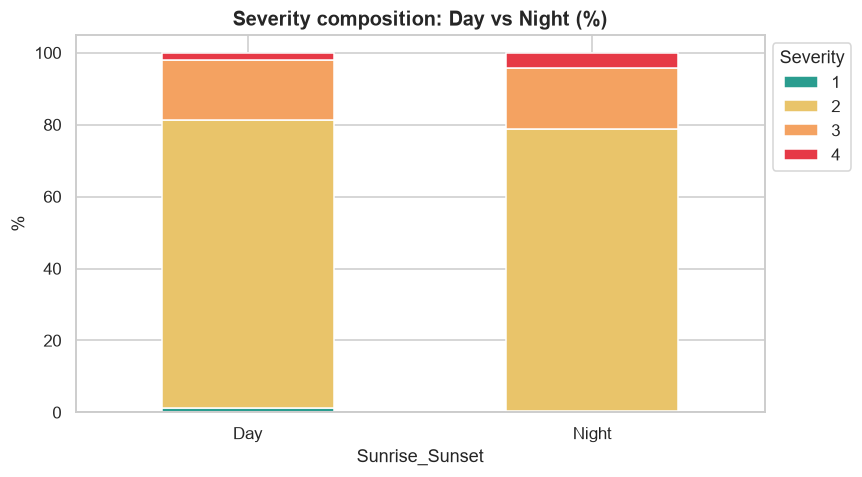

In [30]:
dn = pd.crosstab(df["Sunrise_Sunset"], df["Severity"], normalize="index") * 100
dn.plot(kind="bar", stacked=True, figsize=(8, 4.5), color=[SEV_COLORS[c] for c in dn.columns], rot=0)
plt.title("Severity composition: Day vs Night (%)"); plt.ylabel("%"); plt.legend(title="Severity", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

## 11. Correlation Analysis
### Correlation heatmap – numeric features

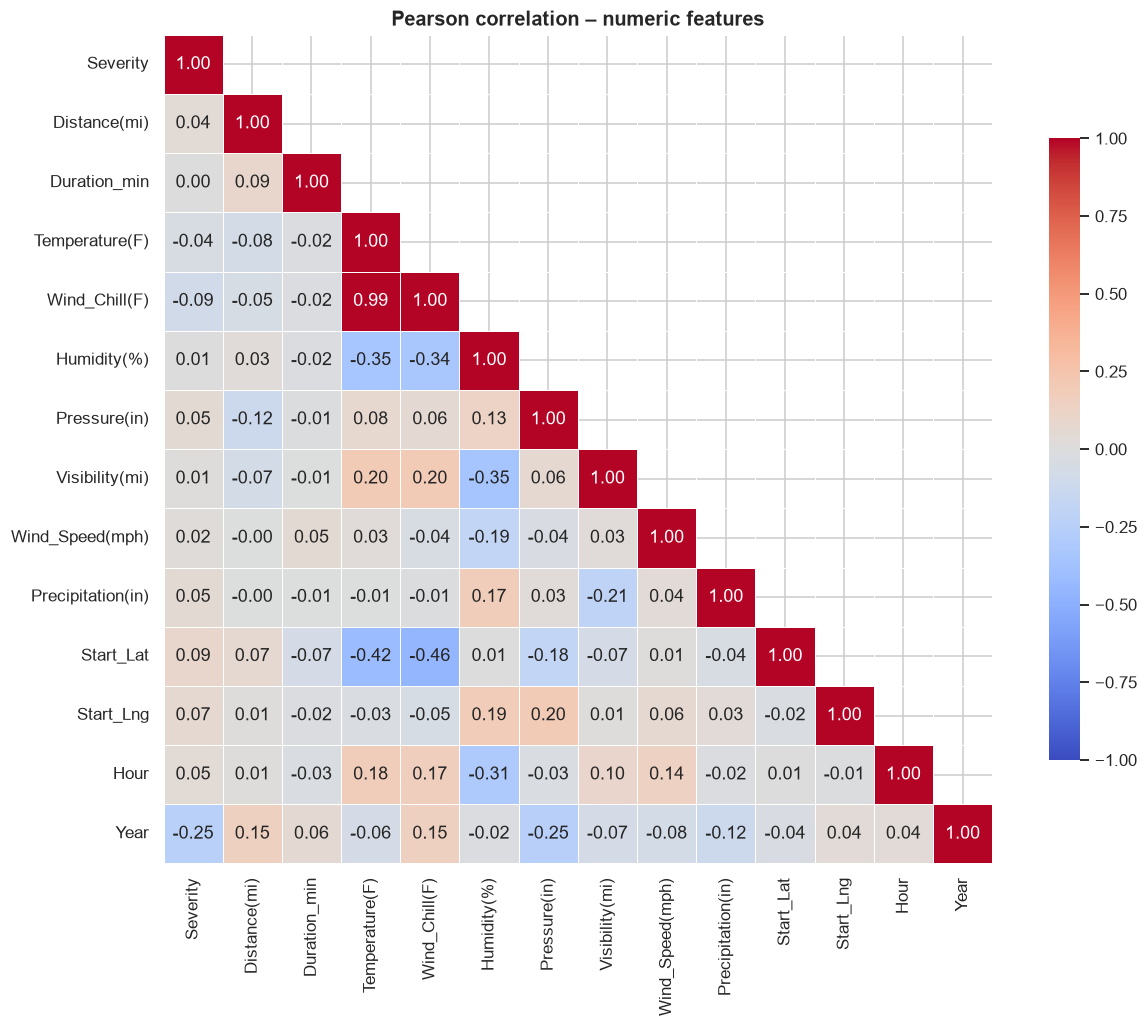

In [31]:
corr_cols = ["Severity", "Distance(mi)", "Duration_min", "Temperature(F)", "Wind_Chill(F)",
             "Humidity(%)", "Pressure(in)", "Visibility(mi)", "Wind_Speed(mph)",
             "Precipitation(in)", "Start_Lat", "Start_Lng", "Hour", "Year"]
corr = df[corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(12, 9.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=.5, linecolor="white", square=True, cbar_kws={"shrink": .75}, ax=ax)
ax.set_title("Pearson correlation – numeric features")
plt.tight_layout(); plt.show()

### Correlation heatmap – Severity, road features and daylight

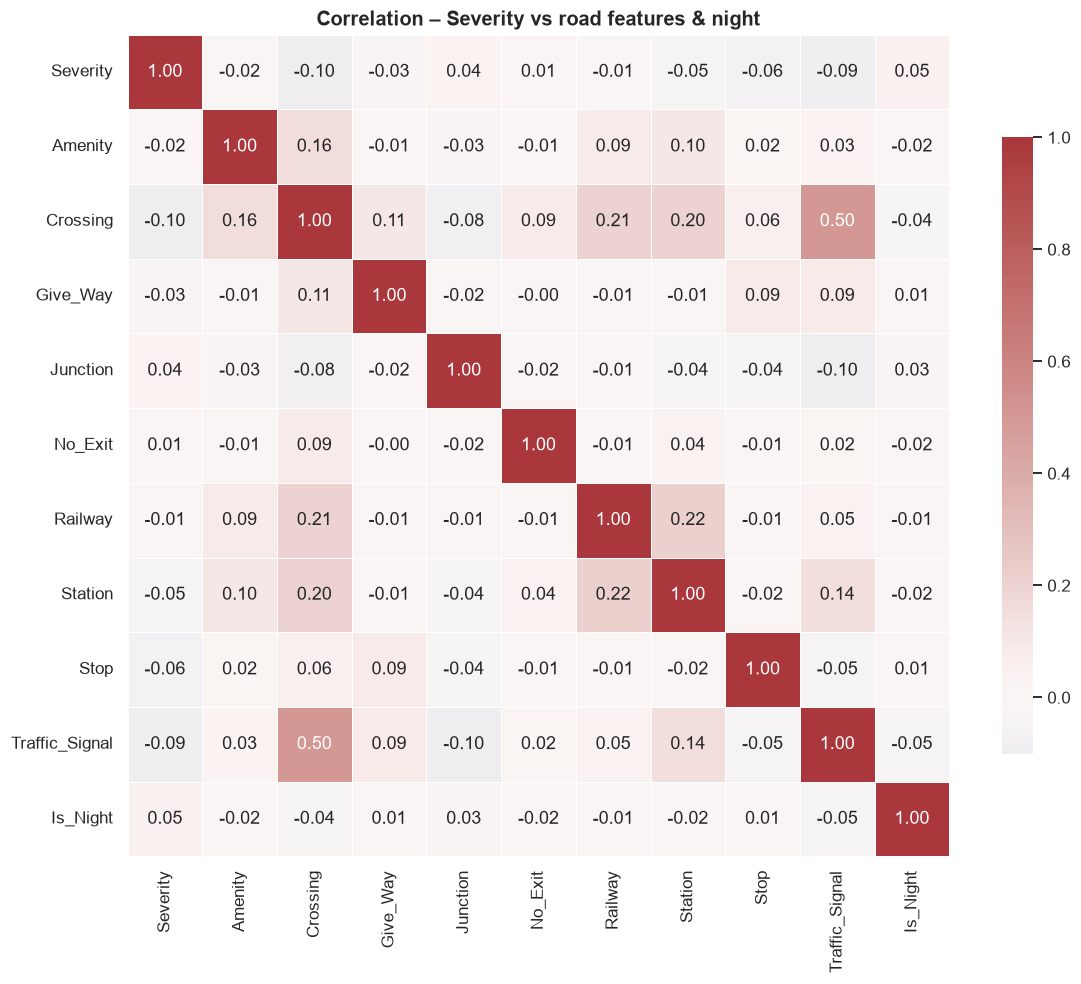

In [32]:
bin_df = df[["Severity"] + ROAD_COLS].astype(float)
bin_df["Is_Night"] = (df["Sunrise_Sunset"] == "Night").astype(float)
bin_df = bin_df.loc[:, bin_df.std() > 0]          # drop constant columns (e.g. Turning_Loop)
c2 = bin_df.corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(c2, annot=True, fmt=".2f", cmap="vlag", center=0, linewidths=.5, linecolor="white",
            square=True, cbar_kws={"shrink": .75}, ax=ax)
ax.set_title("Correlation – Severity vs road features & night")
plt.tight_layout(); plt.show()

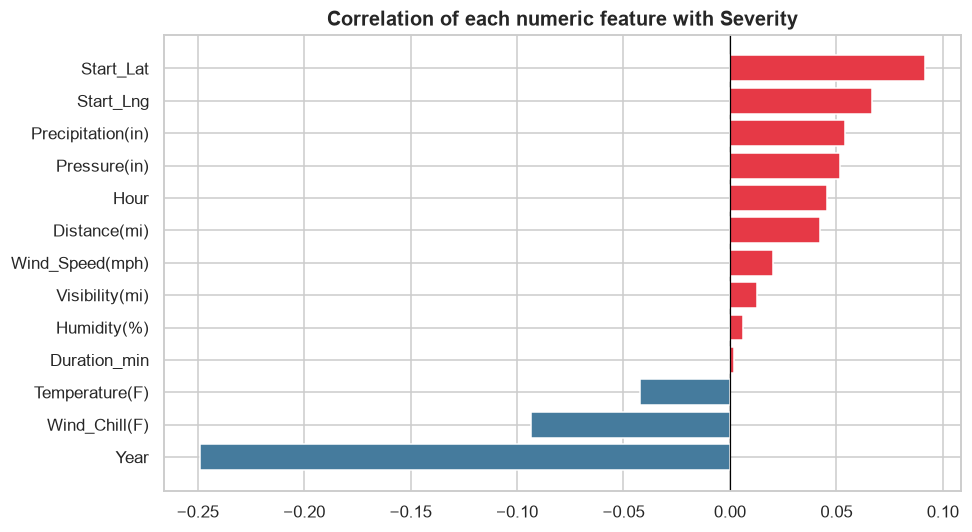

In [33]:
sev_corr = corr["Severity"].drop("Severity").sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(sev_corr.index, sev_corr.values, color=["#e63946" if v > 0 else "#457b9d" for v in sev_corr.values])
ax.axvline(0, color="black", lw=.8)
ax.set_title("Correlation of each numeric feature with Severity")
plt.tight_layout(); plt.show()

## 12. Key Findings
The summary below is computed directly from the data.

In [34]:
sev_share = df["Severity"].value_counts(normalize=True).sort_index() * 100
peak_hour = df["Hour"].value_counts().idxmax()
peak_day = df["Weekday"].value_counts().idxmax()
top3 = df["State"].value_counts(normalize=True).head(3) * 100
top_w = df["Weather_Condition"].value_counts(normalize=True).head(3) * 100
top_road = (df[ROAD_COLS].mean() * 100).sort_values(ascending=False).head(3)
night = (df["Sunrise_Sunset"] == "Night").mean() * 100

print(f"• Dataset: {len(df):,} accidents × {len(ORIGINAL_COLS)} original features, "
      f"{df['Start_Time'].min():%Y-%m-%d} to {df['Start_Time'].max():%Y-%m-%d}.")
print("• Severity: " + ", ".join(f"level {k} = {v:.1f}%" for k, v in sev_share.items())
      + " → strongly imbalanced, dominated by Severity 2.")
print(f"• Busiest year: {df['Year'].value_counts().idxmax()}; busiest weekday: {peak_day}; peak hour: {peak_hour}:00.")
print("• Top states: " + ", ".join(f"{k} ({v:.1f}%)" for k, v in top3.items()) + ".")
print("• Most common weather: " + ", ".join(f"{k} ({v:.1f}%)" for k, v in top_w.items())
      + " → most accidents happen in normal weather.")
print("• Most frequent nearby road features: " + ", ".join(f"{k} ({v:.1f}%)" for k, v in top_road.items()) + ".")
print(f"• {night:.1f}% of accidents occurred at night.")
print(f"• Highest missing rates: " + ", ".join(f"{k} ({v:.1f}%)" for k, v in miss.head(4).items()) + ".")
print(f"• Median duration: {df['Duration_min'].median():.0f} min; median affected distance: {df['Distance(mi)'].median():.2f} mi.")

• Dataset: 2,000 accidents × 46 original features, 2016-04-06 to 2023-03-29.
• Severity: level 1 = 0.9%, level 2 = 79.7%, level 3 = 16.8%, level 4 = 2.6% → strongly imbalanced, dominated by Severity 2.
• Busiest year: 2022; busiest weekday: Friday; peak hour: 7:00.
• Top states: CA (23.0%), FL (10.4%), TX (7.0%).
• Most common weather: Fair (33.2%), Mostly Cloudy (13.8%), Cloudy (11.0%) → most accidents happen in normal weather.
• Most frequent nearby road features: Traffic_Signal (14.7%), Crossing (11.2%), Junction (6.8%).
• 31.5% of accidents occurred at night.
• Highest missing rates: End_Lng (43.5%), End_Lat (43.5%), Precipitation(in) (29.6%), Wind_Chill(F) (26.1%).
• Median duration: 75 min; median affected distance: 0.03 mi.
